# 03 · 不确定度与新增信息：选择下一批结构
**DP-EVA 实验课堂 · 约 10 分钟**

论文已用 3,000 帧训练浅层委员会，并保存了四个模型对 27,656 帧的预测。

本节现场重新计算一小批原始预测的 UQ，再用全量 UQ 调节筛选边界，最后在完整候选池上进行 normal / joint 采样。候选选择不使用 DFT 误差。


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
candidates = [Path.cwd(), Path.cwd() / 'examples/tutorials/paper_case']
TUTORIAL = next((p.resolve() for p in candidates if (p / 'tutorial_support.py').is_file()), None)
if TUTORIAL is None:
    raise RuntimeError('请从仓库根目录或 paper_case 目录启动 Jupyter。')
sys.path.insert(0, str(TUTORIAL))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
import tutorial_support as t
bundle = t.load_bundle()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .15})
print('DP-EVA 源码: 当前仓库 src/dpeva')
print('模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU')


DP-EVA 源码: 当前仓库 src/dpeva
模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU


## 从四个模型的原子力到结构 UQ
模型 0 是继承预训练 fitting 的基准成员，模型 1–3 构成随机初始化 fitting 的委员会。

QbC 衡量委员会内部的分歧，RND 衡量委员会相对模型 0 的偏离。当前 `UQCalculator` 先计算每个原子的力向量分歧，再取每帧最大值。

以下八帧的原始预测来自归档文件，计算后会核对历史 UQ 表。

**浅层委员会负责选数，最终模型负责应用。** 论文中的两类训练如下：

| 用途 | 编码器 | 解码器 / fitting-net | 论文训练步数 |
|---|---|---|---:|
| 基准模型 0：提供参照预测 | 冻结预训练参数 | 从预训练权重初始化后微调 | 10,000 |
| 委员会模型 1–3：提供预测分歧 | 冻结预训练参数 | 各自随机初始化后微调 | 10,000 |
| 最终领域模型：用于精度与应用测试 | 可训练 | 按正式微调设置训练 | 40,000 |

“随机初始化”描述的是训练起点；计算 UQ 时四个模型均已在已有训练集上微调。这里的 RND 指论文中受随机网络蒸馏启发的**力预测偏离指标**，其参照模型 0 也经过微调。冻结编码器减少了需要更新的参数，但并不免除力预测计算。来源：[论文 Methods 与 Dataset and computational details](https://doi.org/10.1093/ce/zkag029)。


In [2]:
probe = t.recompute_probe()
display(probe)
print('八帧 QbC、原始 RND、模型 0 最大力误差与历史表一致。')


,uq_qbc_for,uq_rnd_for,diff_maxf_0_frame
other_dpdata/C8Fe0H10O1-0,0.051406,0.338010,0.437957
other_dpdata/C8Fe0H10O1-1,0.061877,0.209198,0.425510
other_dpdata/C8Fe0H10O1-2,0.078893,0.531881,0.390089
other_dpdata/C8Fe0H10O1-3,0.038019,0.180773,0.237159
other_dpdata/C8Fe0H10O1-4,0.036361,0.179558,0.237715
other_dpdata/C8Fe0H10O1-5,0.069330,0.479725,0.239642
other_dpdata/C8Fe0H10O1-6,0.081245,0.280363,0.622486
other_dpdata/C8Fe0H10O1-7,0.126598,1.028929,1.473587


八帧 QbC、原始 RND、模型 0 最大力误差与历史表一致。


## 将两种 UQ 放到可比较的尺度
历史 RND 已按全候选池的中位数和 IQR 对齐到 QbC 尺度。必须在同一个参考分布上对齐；只拿八帧重新拟合尺度，会改变含义。


In [3]:
from dpeva.uncertain.calculator import UQCalculator
uq = bundle['uq']
rescaled = UQCalculator().align_scales(uq.uq_qbc_for.to_numpy(), uq.uq_rnd_for.to_numpy())
np.testing.assert_allclose(rescaled, uq.uq_rnd_for_rescaled, atol=1e-8)
display(uq.paper_identity.value_counts().rename('历史分类（原自动阈值）').to_frame())


,历史分类（原自动阈值）
paper_identity,
accurate,22217
candidate,5339
failed,100


## 复算论文自动阈值，再现场调整
默认按论文设置从全池 UQ 重新计算自动阈值：KDE 峰高比例 0.50，区间宽度 0.25 eV/Å，两轴独立计算。先核对分类与历史记录，再切换“手动练习”调整区间。

下图左侧显示 0–0.6 范围，区间外点数会注明；右侧统计包含全部 27,656 帧。`accurate`、`candidate`、`failed` 是按 UQ 划分的区域名称，分别表示模型较有信心、待补充学习和高不确定度；真实误差用来检验这种判断。

**两种 UQ 提供互补信息。** 勾选“揭示误差”，观察仅看一个轴会遗漏哪些点，以及低 UQ 区内是否仍有高误差结构。真实误差仅用于事后诊断。这里使用论文 DPA3 数据；SI Figure S2 的早期 DPA-2.3.1 对照作为延伸阅读。

峰高比例 0.50 指 KDE 主峰右侧下降到峰高一半的位置，**不是数据的 50% 分位点**。候选区位于低不确定度区与上界之间，用于本轮补充学习；超出上界的 `failed` 点暂不进入这轮采样，后续可检查结构、模型适用范围和探索条件，类名本身不判定结构是否物理有效。

**现场提问**：如果只按 UQ 从高到低取前 1,000 点，会漏掉哪些考虑？先想一想，再看后面的 joint 结果：不确定度给出模型信息，代表性采样还要处理候选之间及其与训练集的重复。


,下限,上限
qbc,0.072072,0.322072
rnd,0.072072,0.322072


自动 UQ 分类逐帧匹配论文：候选 5,339，准确 22,217，失败 100。


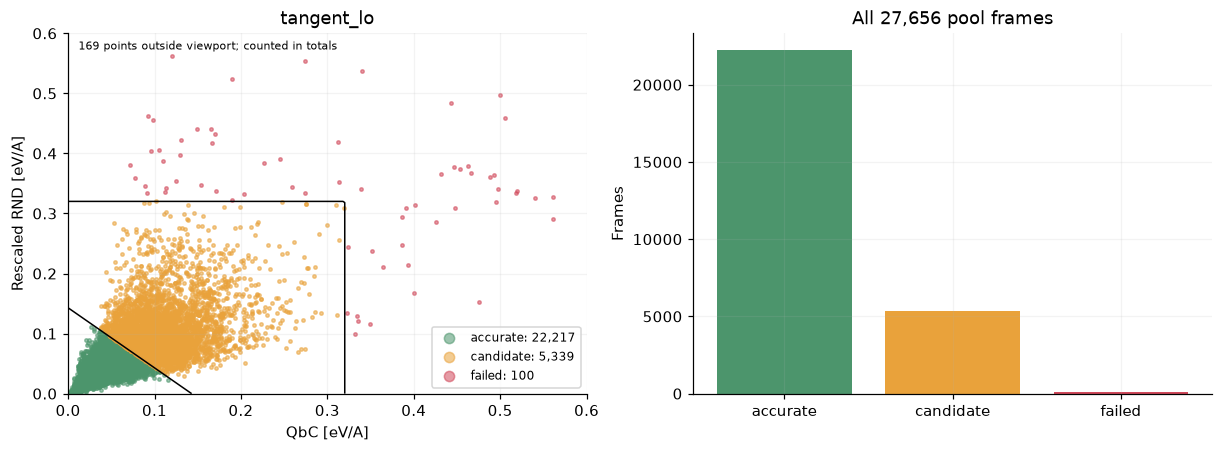

,帧数
accurate,22217
candidate,5339
failed,100


In [4]:
bounds = t.paper_thresholds()
display(pd.DataFrame(bounds, index=['下限', '上限']).T)
labels = t.classify(bundle['uq'])[3]
np.testing.assert_array_equal(labels.to_numpy(), bundle['uq'].paper_identity.to_numpy())
print('自动 UQ 分类逐帧匹配论文：候选 5,339，准确 22,217，失败 100。')
display(pd.Series(t.plot_uq()).to_frame('帧数'))
def change_uq(mode, bounds, scheme, reveal_error):
    if bounds[0] >= bounds[1]:
        print('请拉开区间端点：下限必须小于上限。')
        return
    low, high = bounds if mode == 'manual' else (None, None)
    counts = t.plot_uq(low, high, scheme, reveal_error)
    display(pd.Series(counts).to_frame('帧数'))
widgets.interact(change_uq,
    mode=widgets.Dropdown(options=[('论文自动阈值','auto'),('手动练习','manual')], value='auto', description='阈值模式'),
    bounds=widgets.FloatRangeSlider(value=[.08,.33], min=.01, max=.6, step=.01, description='UQ区间', continuous_update=False),
    scheme=widgets.Dropdown(options=['tangent_lo','circle_lo','strict'], value='tangent_lo', description='边界'),
    reveal_error=widgets.Checkbox(value=False, description='揭示误差'));


**图 6｜双指标 UQ 筛选。** 左图按 QbC 与缩放 RND 将结构分为低不确定度区（accurate）、候选区和高不确定度区（failed），右图统计全池帧数。来源：归档委员会预测产生的 UQ；分类边界由当前代码计算。


## normal 与 joint：已有数据怎样参与选择？
这里默认使用完整的 27,656 个候选池结构和 3,000 个历史训练点，现场实际重跑当前算法；默认 joint 聚类预算为 3,000。慢机器也可选择小切片（512 个池中点 + 256 个训练点），但小切片的训练/候选比例不同，不能外推其新增数量。

Joint 将已有训练点与 UQ 候选一起参与特征变换及聚类，然后只导出来自候选池的点。因此聚类选中总数与**新增标注数**不同。Normal/joint 各自重新拟合 PCA，不能直接逐点比较两个图的坐标；应比较原结构身份与新增数量。

本节沿用论文的历史 3,000 帧训练集及其委员会预测，与第 02 章现场重新选出的集合独立；迭代特征来自原始 iter1 运行，并保留训练特征的加载顺序。论文 normal 分支预算为 1,000，joint 分支为 3,000；默认“论文预算”会随 Joint 开关自动切换；选择“手动练习”后才使用聚类滑块，可用同预算作方法练习。


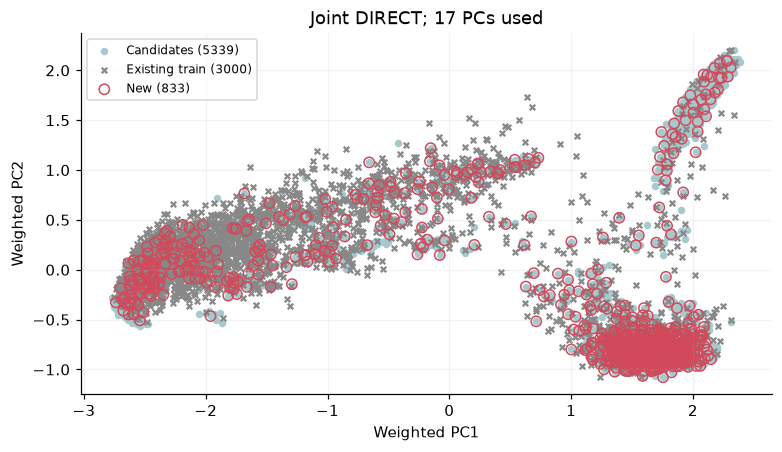

聚类预算 3000；聚类选中 3000；已有训练点 2167；新增 833。


,论文名单对照（选数后）
本次新增,833
历史新增,843
名单交集,737
仅本次,96
仅历史,106
名单完全一致,False


In [5]:
selection = t.plot_sampling(**t.paper_parameters())
display(t.compare_paper_selection(selection))
def change_selection(joint, budget_mode, n_clusters, use_uq, mode, bounds, scheme, scope):
    low, high = bounds if mode == 'manual' else (None, None)
    effective_clusters = None if budget_mode == 'paper' else n_clusters
    try:
        result = t.plot_sampling(joint=joint, n_clusters=effective_clusters, use_uq=use_uq,
                                 low=low, high=high, scheme=scheme, scope=scope)
    except ValueError as error:
        print(error)
        return
    display(pd.Series({k: result[k] for k in ['candidate_count','selected_total','selected_training_count','retained_pcs']}).to_frame('本次结果'))
widgets.interact_manual.options(manual_name='运行采样')(change_selection,
    joint=widgets.Checkbox(value=True, description='Joint'),
    budget_mode=widgets.Dropdown(options=[('论文预算','paper'),('手动练习','manual')], value='paper', description='预算模式'),
    n_clusters=widgets.SelectionSlider(options=[48,300,1000,2000,3000], value=3000, description='手动聚类数', continuous_update=False),
    use_uq=widgets.Checkbox(value=True, description='启用UQ'),
    mode=widgets.Dropdown(options=[('论文自动阈值','auto'),('手动练习','manual')], value='auto', description='阈值模式'),
    bounds=widgets.FloatRangeSlider(value=[.08,.33], min=.01, max=.6, step=.01, description='采样UQ区间', continuous_update=False),
    scheme=widgets.Dropdown(options=['tangent_lo','circle_lo','strict'], value='tangent_lo', description='采样边界'),
    scope=widgets.Dropdown(options=[('全量','full'), ('小切片','small')], value='full', description='数据范围'));


**图 7｜已有训练点参与联合采样。** 浅蓝点为 UQ 候选，灰叉为已有训练点，红圈为新增结构。只将红圈对应的结构交给标注。来源：当前 DP-EVA 的实际 joint 采样结果。

## 固定一次选择并导出
上方控件用于探索；下面显式列出最终参数并重新运行，使导出与参数一一对应。结构导出不附带已有能量和力标签，符合交给标注阶段的输入含义。

每次运行写入新的 `work/selection-*/`；`selected.csv` 同时保留候选池局部帧号与完整原数据的 `source_dataname`。不会覆盖上一次导出，也不会提交计算任务。


In [6]:
parameters = t.paper_parameters()
selection = t.sample_live(**parameters)
if len(selection['selected_pool_indices']):
    output = t.export_selection(selection['selected_pool_indices'])
    import json
    (output / 'parameters.json').write_text(json.dumps(dict(parameters, resolved_thresholds=t.uq_thresholds(parameters['low'], parameters['high'])), indent=2) + '\n')
    print('导出:', output.relative_to(TUTORIAL))
    display(pd.read_csv(output / 'selected.csv').head())
else:
    print('没有候选，请扩大 UQ 区间后重新执行。')


导出: work/selection-0fj3dfkm


,export_system,pool_index,dataname,source_dataname
0,frame_0000,26483,other_dpdata/C11Fe28H1O2-129,C11Fe28H1O2-172
1,frame_0001,6334,other_dpdata/C9Fe12H0O2-0,C9Fe12H0O2-0
2,frame_0002,13970,other_dpdata/C6Fe0H12O6-2270,C6Fe0H12O6-2409
3,frame_0003,3366,other_dpdata/C15Fe0H18O3-4,C15Fe0H18O3-4
4,frame_0004,2891,other_dpdata/C0Fe12H4O0-173,C0Fe12H4O0-177


**练习**：把 UQ 关闭，或者把 joint 关闭，比较导出的结构身份。阈值范围与聚类预算分别控制哪个环节？

**Joint 的作用是让已有数据参与选择，把新增预算更多地用于补充已有训练集。** 补充核查将两种方法的选点映射到同一联合 PCA 空间：相同新增 833 点时，joint 到已有训练集的最近距离中位数约为 **0.088**，normal 约为 **0.081**；历史名单约为 **0.087**。这支持本案例中 joint 更偏向距离已有训练点较远结构的趋势。距离是无量纲的特征空间诊断，分箱覆盖率等其他指标需分别观察。

以上是 [保存的补充核查](data/conclusion_audit.json)，不随控件自动更新。本节使用原实验全量输入、自动阈值和聚类预算；本地核查新增 833 点，历史新增 843 点。加上初始 3,000 帧后，两者均约占全量数据的 **12.5%**。

名单交集用于追溯身份。判断本节结果时，关注 UQ 划分、数据预算和新增信息趋势；近等距选点差异的详细记录见 [复现核查](REPRODUCIBILITY.md)。


## 课后推导：把代码与公式对应起来（现场可跳过）
设同一帧中原子 $i$ 的模型力为 $\mathbf F_i^{(m)}$，委员会成员 $m=1,2,3$ 的平均为 $\overline{\mathbf F}_i$，模型 0 为基准。当前实现为

$$
\epsilon_{\mathrm{qbc}}=\max_i\sqrt{\frac{1}{3}\sum_{m=1}^{3}\left\|\mathbf F_i^{(m)}-\overline{\mathbf F}_i\right\|^2},\qquad
\epsilon_{\mathrm{rnd}}=\max_i\sqrt{\frac{1}{3}\sum_{m=1}^{3}\left\|\mathbf F_i^{(m)}-\mathbf F_i^{(0)}\right\|^2}.
$$

先计算每个原子的力向量分歧，再取帧内最大值，单位为 eV/Å；QbC 的委员会均值不包含模型 0。与第 02、04 章汇总所有验证数据的力 RMSE 相比，这里强调的是一帧内最不确定的原子。

在整个参考池上记两种指标的中位数为 $M_q,M_r$，四分位距为 $I_q,I_r$，则尺度对齐为

$$
\epsilon_{\mathrm{rnd}}^*=\frac{\epsilon_{\mathrm{rnd}}-M_r}{I_r}I_q+M_q.
$$

它使两轴的中位数与四分位距可比，便于组合分类；它不是用 DFT 误差拟合出的校准关系。

**自检**：如果三个委员会成员预测完全一致，但都偏离模型 0，QbC 与 RND 各会怎样？QbC 为零，RND 可以非零，说明第二个比较维度能够补充信息；真实误差仍需标签检验。

公式对应 [论文 Methods](https://doi.org/10.1093/ce/zkag029) 和仓库 [UQCalculator](../../../src/dpeva/uncertain/calculator.py)。延伸阅读见 [参考资料](REFERENCES.md)。
